In [1]:
# CELL 1: Environment Setup, GPU Check & Processed Data Verification
import os
import torch
import pandas as pd
from google.colab import drive

print("=== 1. Mounting Google Drive ===")
try:
    drive.mount('/content/drive', force_remount=True)
    DRIVE_BASE = "/content/drive/MyDrive"
except Exception:
    drive.mount('/content/gdrive', force_remount=True)
    DRIVE_BASE = "/content/gdrive/MyDrive"

# Define project directories
PROJECT_DIR = os.path.join(DRIVE_BASE, "VeritasNet")
PROCESSED_DIR = os.path.join(PROJECT_DIR, "data/processed")
MODELS_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

for d in [PROCESSED_DIR, MODELS_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

print(f"\n📂 Project Directory : {PROJECT_DIR}")
print(f"📂 Processed Data Dir: {PROCESSED_DIR}")

# Hardware verification
print("\n=== 2. Hardware Diagnostics ===")
gpu_available = torch.cuda.is_available()
print(f"🎮 GPU Available: {gpu_available}")
if gpu_available:
    print(f"   - GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"   - Memory: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print("⚠️ WARNING: GPU not detected. Go to Runtime > Change runtime type > Select T4 GPU.")

# Verify files from Notebook 2
print("\n=== 3. Checking Required Artifacts ===")
expected_files = [
    os.path.join(PROCESSED_DIR, "train_text.csv"),
    os.path.join(PROCESSED_DIR, "val_text.csv"),
    os.path.join(PROCESSED_DIR, "test_text.csv"),
    os.path.join(PROCESSED_DIR, "train_full.parquet"),
    os.path.join(PROCESSED_DIR, "val_full.parquet"),
    os.path.join(PROCESSED_DIR, "test_full.parquet"),
    os.path.join(MODELS_DIR, "tfidf_vectorizer.pkl"),
    os.path.join(MODELS_DIR, "resnet_preprocess.pkl")
]

all_present = True
for fpath in expected_files:
    fname = os.path.basename(fpath)
    exists = os.path.exists(fpath)
    status = "✅ Found" if exists else "❌ Missing"
    print(f"{status:<12} : {fname}")
    if not exists:
        all_present = False

if all_present:
    print("\n🚀 All required artifacts are verified and ready!")
else:
    print("\n⚠️ Some files are missing. Please check your data/processed folder.")


=== 1. Mounting Google Drive ===
Mounted at /content/drive

📂 Project Directory : /content/drive/MyDrive/VeritasNet
📂 Processed Data Dir: /content/drive/MyDrive/VeritasNet/data/processed

=== 2. Hardware Diagnostics ===
🎮 GPU Available: True
   - GPU Model: Tesla T4
   - Memory: 14.56 GB

=== 3. Checking Required Artifacts ===
✅ Found      : train_text.csv
✅ Found      : val_text.csv
✅ Found      : test_text.csv
✅ Found      : train_full.parquet
✅ Found      : val_full.parquet
✅ Found      : test_full.parquet
✅ Found      : tfidf_vectorizer.pkl
✅ Found      : resnet_preprocess.pkl

🚀 All required artifacts are verified and ready!


=== 1. Loading Text Splits & Fitted Vectorizer ===
Loaded Train: 6997 | Val: 1500 | Test: 1500
Fitted TF-IDF Vocabulary: 5000 features
Feature Matrix Shapes -> Train: (6997, 5000) | Val: (1500, 5000) | Test: (1500, 5000)

=== 2. Training Logistic Regression Classifier ===
✅ Baseline Model Trained!

================ TRAIN SPLIT EVALUATION ================
🎯 Accuracy: 0.8631

Classification Report:
              precision    recall  f1-score   support

           0     0.8273    0.9176    0.8701      3497
           1     0.9076    0.8086    0.8552      3500

    accuracy                         0.8631      6997
   macro avg     0.8675    0.8631    0.8627      6997
weighted avg     0.8675    0.8631    0.8627      6997


================ VALIDATION SPLIT EVALUATION ================
🎯 Accuracy: 0.7327

Classification Report:
              precision    recall  f1-score   support

           0     0.7046    0.8013    0.7498       750
           1     0.7697    0.6640    0.7130       750

   

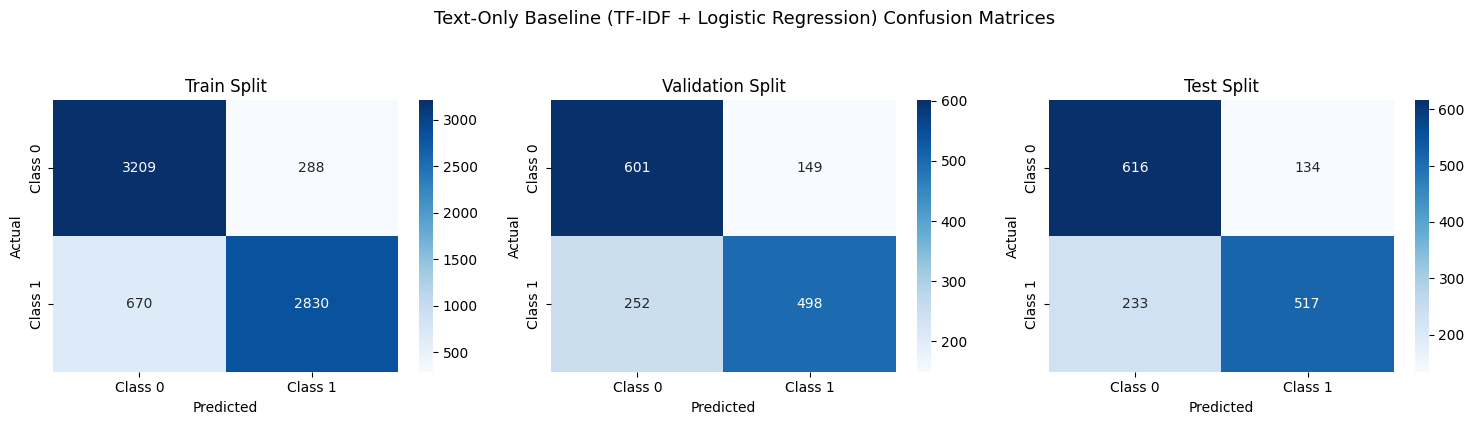

In [2]:
# CELL 2: Text-Only Baseline with Multi-Split Evaluation & Diagnostic Plots
import os
import joblib
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("=== 1. Loading Text Splits & Fitted Vectorizer ===")
train_df = pd.read_csv(os.path.join(PROCESSED_DIR, "train_text.csv"))
val_df   = pd.read_csv(os.path.join(PROCESSED_DIR, "val_text.csv"))
test_df  = pd.read_csv(os.path.join(PROCESSED_DIR, "test_text.csv"))

vectorizer_path = os.path.join(MODELS_DIR, "tfidf_vectorizer.pkl")
vectorizer = joblib.load(vectorizer_path)

print(f"Loaded Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print(f"Fitted TF-IDF Vocabulary: {len(vectorizer.vocabulary_)} features")

# Transform splits into sparse TF-IDF matrices (Zero-Leakage)
X_train = vectorizer.transform(train_df['cleaned_text'])
X_val   = vectorizer.transform(val_df['cleaned_text'])
X_test  = vectorizer.transform(test_df['cleaned_text'])

y_train = train_df['label'].values
y_val   = val_df['label'].values
y_test  = test_df['label'].values

print(f"Feature Matrix Shapes -> Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

print("\n=== 2. Training Logistic Regression Classifier ===")
# L2 regularized logistic regression (C=1.0)
baseline_model = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
baseline_model.fit(X_train, y_train)
print("✅ Baseline Model Trained!")

# Multi-split evaluation function
def run_split_eval(X_mat, y_true, split_name):
    y_pred = baseline_model.predict(X_mat)
    acc = accuracy_score(y_true, y_pred)
    print(f"\n================ {split_name.upper()} SPLIT EVALUATION ================")
    print(f"🎯 Accuracy: {acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, digits=4))
    return y_pred, acc

y_pred_train, acc_train = run_split_eval(X_train, y_train, "Train")
y_pred_val,   acc_val   = run_split_eval(X_val,   y_val,   "Validation")
y_pred_test,  acc_test  = run_split_eval(X_test,  y_test,  "Test")

# Save the trained baseline artifact to Google Drive
baseline_save_path = os.path.join(MODELS_DIR, "text_baseline_model.pkl")
joblib.dump(baseline_model, baseline_save_path)
print(f"\n💾 Saved baseline model to: {baseline_save_path}")

# Plot and save confusion matrices across all splits
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
eval_splits = [
    ("Train", y_train, y_pred_train),
    ("Validation", y_val, y_pred_val),
    ("Test", y_test, y_pred_test)
]

for i, (name, y_true, y_pred) in enumerate(eval_splits):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Class 0', 'Class 1'],
                yticklabels=['Class 0', 'Class 1'])
    axes[i].set_title(f'{name} Split')
    axes[i].set_ylabel('Actual')
    axes[i].set_xlabel('Predicted')

plt.suptitle('Text-Only Baseline (TF-IDF + Logistic Regression) Confusion Matrices', y=1.05, fontsize=13)
plt.tight_layout()
cm_save_path = os.path.join(RESULTS_DIR, "text_baseline_multi_set_confusion_matrix.png")
plt.savefig(cm_save_path, bbox_inches='tight')
print(f"📊 Saved multi-split confusion matrix plot to: {cm_save_path}")
plt.show()


In [3]:
# CELL 3: Image Feature Extraction using Pretrained ResNet-18
import os
import io
import torch
import torchvision.models as models
import numpy as np
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.notebook import tqdm
import joblib

# Device configuration (GPU check)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device for feature extraction: {device}")
if device.type == "cpu":
    print("⚠️ Warning: Running on CPU will be slower. Ensure GPU is enabled in Runtime settings.")

# Directory paths
PROCESSED_DIR = os.path.join(PROJECT_DIR, "data/processed")
MODELS_DIR = os.path.join(PROJECT_DIR, "models")

# 1. Custom Dataset for Streaming Parquet Image Decoding
class ParquetImageDataset(Dataset):
    def __init__(self, parquet_path, transform=None):
        self.df = pd.read_parquet(parquet_path)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_bytes = row['image']['bytes']

        # Decode binary bytes to RGB PIL Image
        img = Image.open(io.BytesIO(img_bytes)).convert("RGB")

        if self.transform:
            img = self.transform(img)

        return img, idx

# 2. Load Torchvision Preprocessing Pipeline & ResNet-18 Backbone
print("\n=== 1. Loading Pretrained ResNet-18 Backbone ===")
preprocess = joblib.load(os.path.join(MODELS_DIR, "resnet_preprocess.pkl"))

# Initialize ResNet-18 with default ImageNet weights
resnet18 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Strip the final 1000-class linear layer by replacing it with an Identity pass-through
resnet18.fc = torch.nn.Identity()

# Move to GPU and set to evaluation mode (freezes BatchNorm running stats)
resnet18 = resnet18.to(device)
resnet18.eval()
print("✅ ResNet-18 loaded with ImageNet weights and classification head bypassed.")

# 3. Batch-Wise Feature Extraction Function
def extract_and_save_features(split_name):
    parquet_path = os.path.join(PROCESSED_DIR, f"{split_name}_full.parquet")
    save_path = os.path.join(PROCESSED_DIR, f"{split_name}_image_features.npy")

    print(f"\n--- Extracting Features for {split_name.upper()} Split ---")
    dataset = ParquetImageDataset(parquet_path, transform=preprocess)
    dataloader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=2)

    features_list = []

    # Disable gradient tracking to conserve GPU VRAM
    with torch.no_grad():
        for imgs, _ in tqdm(dataloader, desc=f"Processing {split_name}"):
            imgs = imgs.to(device)
            feats = resnet18(imgs)  # Outputs (batch_size, 512)
            features_list.append(feats.cpu().numpy())

    # Concatenate all batches into a single 2D NumPy array
    all_features = np.concatenate(features_list, axis=0)
    np.save(save_path, all_features)

    print(f"✅ Extracted shape for {split_name}: {all_features.shape}")
    print(f"💾 Saved to: {save_path}")
    return all_features.shape

# Execute extraction across all three splits
train_feat_shape = extract_and_save_features("train")
val_feat_shape   = extract_and_save_features("val")
test_feat_shape  = extract_and_save_features("test")

print("\n🚀 All image features extracted and cached successfully to Google Drive!")


Using device for feature extraction: cuda

=== 1. Loading Pretrained ResNet-18 Backbone ===
✅ ResNet-18 loaded with ImageNet weights and classification head bypassed.

--- Extracting Features for TRAIN Split ---


Processing train:   0%|          | 0/110 [00:00<?, ?it/s]

✅ Extracted shape for train: (6997, 512)
💾 Saved to: /content/drive/MyDrive/VeritasNet/data/processed/train_image_features.npy

--- Extracting Features for VAL Split ---


Processing val:   0%|          | 0/24 [00:00<?, ?it/s]

✅ Extracted shape for val: (1500, 512)
💾 Saved to: /content/drive/MyDrive/VeritasNet/data/processed/val_image_features.npy

--- Extracting Features for TEST Split ---


Processing test:   0%|          | 0/24 [00:00<?, ?it/s]

✅ Extracted shape for test: (1500, 512)
💾 Saved to: /content/drive/MyDrive/VeritasNet/data/processed/test_image_features.npy

🚀 All image features extracted and cached successfully to Google Drive!


In [4]:
# CELL 4: Multimodal PyTorch Dataset & Batch DataLoaders
import os
import joblib
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader

print("=== 1. Loading Text Data, Precomputed Image Features & Vectorizer ===")
PROCESSED_DIR = os.path.join(PROJECT_DIR, "data/processed")
MODELS_DIR = os.path.join(PROJECT_DIR, "models")

# Load text data splits
train_df = pd.read_csv(os.path.join(PROCESSED_DIR, "train_text.csv"))
val_df   = pd.read_csv(os.path.join(PROCESSED_DIR, "val_text.csv"))
test_df  = pd.read_csv(os.path.join(PROCESSED_DIR, "test_text.csv"))

# Load precomputed 512-D ResNet-18 feature arrays
train_img_feats = np.load(os.path.join(PROCESSED_DIR, "train_image_features.npy"))
val_img_feats   = np.load(os.path.join(PROCESSED_DIR, "val_image_features.npy"))
test_img_feats  = np.load(os.path.join(PROCESSED_DIR, "test_image_features.npy"))

# Load fitted TF-IDF vectorizer and transform text to sparse matrices
vectorizer = joblib.load(os.path.join(MODELS_DIR, "tfidf_vectorizer.pkl"))
X_train_sparse = vectorizer.transform(train_df['cleaned_text'])
X_val_sparse   = vectorizer.transform(val_df['cleaned_text'])
X_test_sparse  = vectorizer.transform(test_df['cleaned_text'])

y_train = train_df['label'].values.astype(np.float32)
y_val   = val_df['label'].values.astype(np.float32)
y_test  = test_df['label'].values.astype(np.float32)

print(f"Train - Text: {X_train_sparse.shape}, Image Features: {train_img_feats.shape}, Labels: {len(y_train)}")
print(f"Val   - Text: {X_val_sparse.shape}, Image Features: {val_img_feats.shape}, Labels: {len(y_val)}")
print(f"Test  - Text: {X_test_sparse.shape}, Image Features: {test_img_feats.shape}, Labels: {len(y_test)}")

# 2. Define Multimodal PyTorch Dataset
class MultimodalDataset(Dataset):
    def __init__(self, text_sparse_matrix, image_features, labels):
        self.text_sparse = text_sparse_matrix.tocsr()  # Efficient row indexing
        self.image_features = image_features.astype(np.float32)
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # Convert only the single required row to a dense float32 array
        text_dense = self.text_sparse[idx].toarray().squeeze(0).astype(np.float32)
        img_feat = self.image_features[idx]
        label = self.labels[idx]

        return {
            'text_features': torch.tensor(text_dense, dtype=torch.float32),
            'image_features': torch.tensor(img_feat, dtype=torch.float32),
            'label': torch.tensor(label, dtype=torch.float32)
        }

# 3. Instantiate Datasets and DataLoaders
BATCH_SIZE = 32

train_dataset = MultimodalDataset(X_train_sparse, train_img_feats, y_train)
val_dataset   = MultimodalDataset(X_val_sparse, val_img_feats, y_val)
test_dataset  = MultimodalDataset(X_test_sparse, test_img_feats, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"\n✅ DataLoaders initialized (Batch Size: {BATCH_SIZE})")
print(f"   - Train batches: {len(train_loader)}")
print(f"   - Val batches  : {len(val_loader)}")
print(f"   - Test batches : {len(test_loader)}")

# 4. Verify Single Batch Shapes
sample_batch = next(iter(train_loader))
print("\n=== 2. Diagnostic Sample Batch Verification ===")
print(f"🔑 text_features shape  : {sample_batch['text_features'].shape}  (Expected: [{BATCH_SIZE}, 5000])")
print(f"🔑 image_features shape : {sample_batch['image_features'].shape}  (Expected: [{BATCH_SIZE}, 512])")
print(f"🔑 label shape          : {sample_batch['label'].shape}  (Expected: [{BATCH_SIZE}])")


=== 1. Loading Text Data, Precomputed Image Features & Vectorizer ===
Train - Text: (6997, 5000), Image Features: (6997, 512), Labels: 6997
Val   - Text: (1500, 5000), Image Features: (1500, 512), Labels: 1500
Test  - Text: (1500, 5000), Image Features: (1500, 512), Labels: 1500

✅ DataLoaders initialized (Batch Size: 32)
   - Train batches: 219
   - Val batches  : 47
   - Test batches : 47

=== 2. Diagnostic Sample Batch Verification ===
🔑 text_features shape  : torch.Size([32, 5000])  (Expected: [32, 5000])
🔑 image_features shape : torch.Size([32, 512])  (Expected: [32, 512])
🔑 label shape          : torch.Size([32])  (Expected: [32])


In [5]:
# CELL 5: Simple Multimodal Fusion Network
#Custom Multimodal PyTorch MLP Fusion Model Definition & Forward Pass Test
import torch
import torch.nn as nn

# 1. Check GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# 2. Define the Model
class VeritasNetFusion(nn.Module):
    def __init__(self):
        super().__init__()
        # Compress text: 5000 -> 256
        self.text_layer = nn.Sequential(
            nn.Linear(5000, 256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        # Compress image: 512 -> 256
        self.image_layer = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        # Combined classifier: 512 (256 text + 256 image) -> 1 score
        self.classifier = nn.Sequential(
            nn.Linear(512, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1)
        )

    def forward(self, text, image):
        t = self.text_layer(text)         # Shape: [batch, 256]
        img = self.image_layer(image)     # Shape: [batch, 256]

        combined = torch.cat((t, img), dim=1)  # Glue together: [batch, 512]
        out = self.classifier(combined)        # Output score: [batch, 1]
        return out.squeeze(1)                  # Shape: [batch]

# 3. Create Model
model = VeritasNetFusion().to(device)
print(model)

# 4. Quick Test Run on 1 batch from train_loader
batch = next(iter(train_loader))
text_data = batch['text_features'].to(device)
img_data = batch['image_features'].to(device)

output = model(text_data, img_data)
print("\nTest batch successful!")
print("Input batch size :", text_data.shape[0])
print("Output scores    :", output.shape)  # Should be [32]


Using: cuda
VeritasNetFusion(
  (text_layer): Sequential(
    (0): Linear(in_features=5000, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
  )
  (image_layer): Sequential(
    (0): Linear(in_features=512, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
  )
  (classifier): Sequential(
    (0): Linear(in_features=512, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)

Test batch successful!
Input batch size : 32
Output scores    : torch.Size([32])


=== Starting Training (10 Epochs) ===
Epoch 01/10 | Train Loss: 0.4919 | Val Accuracy: 0.8080 ⭐ [Saved Best Model]
Epoch 02/10 | Train Loss: 0.2703 | Val Accuracy: 0.8580 ⭐ [Saved Best Model]
Epoch 03/10 | Train Loss: 0.1724 | Val Accuracy: 0.8607 ⭐ [Saved Best Model]
Epoch 04/10 | Train Loss: 0.1234 | Val Accuracy: 0.8460
Epoch 05/10 | Train Loss: 0.0912 | Val Accuracy: 0.8507
Epoch 06/10 | Train Loss: 0.0669 | Val Accuracy: 0.8407
Epoch 07/10 | Train Loss: 0.0568 | Val Accuracy: 0.8340
Epoch 08/10 | Train Loss: 0.0514 | Val Accuracy: 0.8313
Epoch 09/10 | Train Loss: 0.0352 | Val Accuracy: 0.8487
Epoch 10/10 | Train Loss: 0.0260 | Val Accuracy: 0.8420

Finished! Best Validation Accuracy: 0.8607
Saved best checkpoint to: /content/drive/MyDrive/VeritasNet/models/veritasnet_best_model.pt
📊 Saved Loss Curve plot to: /content/drive/MyDrive/VeritasNet/results/epoch_vs_loss_curves.png


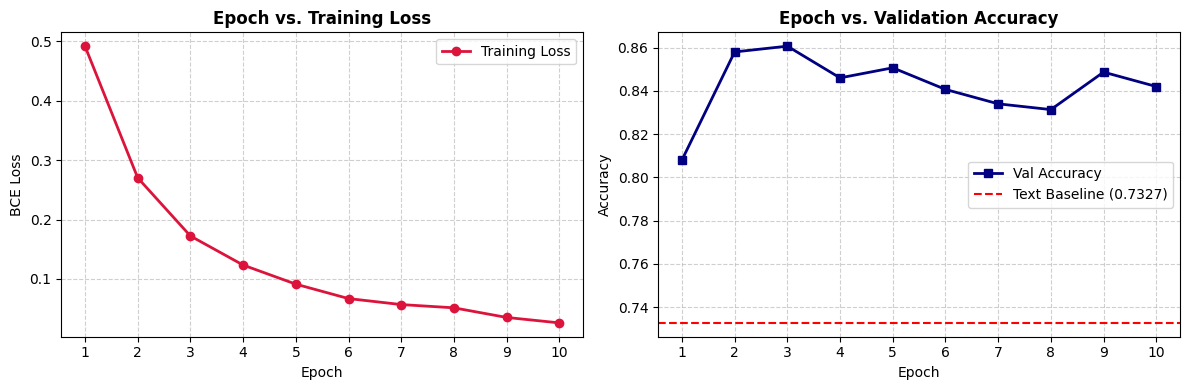

In [6]:
# CELL 6: Training Loop (Stage 1 - Frozen Backbone) with Epoch vs. Loss Curve Plotting
import os
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# 1. Loss function and Optimizer
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 10
best_acc = 0.0
save_path = os.path.join(MODELS_DIR, "veritasnet_best_model.pt")

# Tracking lists for plotting curves
train_losses = []
val_accuracies = []

print("=== Starting Training (10 Epochs) ===")

# 2. Train for 10 epochs
for epoch in range(1, EPOCHS + 1):
    # --- TRAINING PHASE ---
    model.train()
    total_train_loss = 0.0

    for batch in train_loader:
        text_data = batch['text_features'].to(device)
        img_data  = batch['image_features'].to(device)
        labels    = batch['label'].to(device)

        optimizer.zero_grad()
        predictions = model(text_data, img_data)
        loss = loss_fn(predictions, labels)
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # --- VALIDATION PHASE ---
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for batch in val_loader:
            text_data = batch['text_features'].to(device)
            img_data  = batch['image_features'].to(device)
            labels    = batch['label'].to(device)

            predictions = model(text_data, img_data)
            predicted_classes = (predictions >= 0.0).float()

            correct += (predicted_classes == labels).sum().item()
            total += len(labels)

    val_acc = correct / total
    val_accuracies.append(val_acc)

    # Save the model if it achieves the highest validation accuracy so far
    saved = ""
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), save_path)
        saved = " ⭐ [Saved Best Model]"

    print(f"Epoch {epoch:02d}/{EPOCHS:02d} | Train Loss: {avg_train_loss:.4f} | Val Accuracy: {val_acc:.4f}{saved}")

print(f"\nFinished! Best Validation Accuracy: {best_acc:.4f}")
print("Saved best checkpoint to:", save_path)

# 3. Plot Epoch vs. Loss and Validation Accuracy Curves
plt.figure(figsize=(12, 4))

# Subplot 1: Epoch vs. Training Loss
plt.subplot(1, 2, 1)
plt.plot(range(1, EPOCHS + 1), train_losses, marker='o', color='crimson', linewidth=2, label='Training Loss')
plt.title('Epoch vs. Training Loss', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('BCE Loss', fontsize=10)
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# Subplot 2: Epoch vs. Validation Accuracy
plt.subplot(1, 2, 2)
plt.plot(range(1, EPOCHS + 1), val_accuracies, marker='s', color='navy', linewidth=2, label='Val Accuracy')
plt.axhline(y=0.7327, color='red', linestyle='--', label='Text Baseline (0.7327)')
plt.title('Epoch vs. Validation Accuracy', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Accuracy', fontsize=10)
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()

# Save the plot directly to Google Drive
plot_save_path = os.path.join(RESULTS_DIR, "epoch_vs_loss_curves.png")
plt.savefig(plot_save_path, bbox_inches='tight', dpi=300)
print(f"📊 Saved Loss Curve plot to: {plot_save_path}")
plt.show()


✅ Loaded optimal checkpoint weights (from Epoch 2)!

================ FINAL TEST SET EVALUATION ================
🎯 Multimodal Test Accuracy      : 0.8573
📌 Text-Only Baseline Test Acc   : 0.7553
🚀 Multimodal Model beats baseline by +10.20%!

📝 Detailed Classification Report:
              precision    recall  f1-score   support

         0.0     0.8418    0.8800    0.8605       750
         1.0     0.8743    0.8347    0.8540       750

    accuracy                         0.8573      1500
   macro avg     0.8581    0.8573    0.8573      1500
weighted avg     0.8581    0.8573    0.8573      1500


📊 Saved test confusion matrix to: /content/drive/MyDrive/VeritasNet/results/multimodal_test_confusion_matrix.png


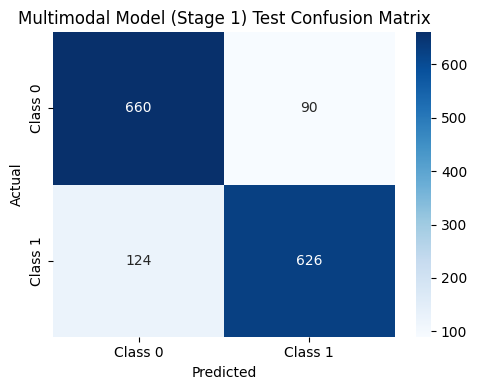

In [7]:
# CELL 7: Multimodal Test Evaluation & Comparison
import os
import torch
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the best saved checkpoint
model_path = os.path.join(MODELS_DIR, "veritasnet_best_model.pt")
model.load_state_dict(torch.load(model_path))
model.eval()
print("✅ Loaded optimal checkpoint weights (from Epoch 2)!")

# 2. Run inference on unseen test set
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        text = batch['text_features'].to(device)
        img  = batch['image_features'].to(device)
        lbl  = batch['label']

        preds = (model(text, img) >= 0.0).float().cpu()
        all_preds.extend(preds.numpy())
        all_labels.extend(lbl.numpy())

# 3. Calculate metrics and baseline comparison
test_acc = accuracy_score(all_labels, all_preds)
print(f"\n================ FINAL TEST SET EVALUATION ================")
print(f"🎯 Multimodal Test Accuracy      : {test_acc:.4f}")
print(f"📌 Text-Only Baseline Test Acc   : 0.7553")

diff = (test_acc - 0.7553) * 100
if diff > 0:
    print(f"🚀 Multimodal Model beats baseline by +{diff:.2f}%!")
else:
    print(f"Baseline difference: {diff:.2f}%")

print("\n📝 Detailed Classification Report:")
print(classification_report(all_labels, all_preds, digits=4))

# 4. Plot and save Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'])
plt.title('Multimodal Model (Stage 1) Test Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()

save_fig_path = os.path.join(RESULTS_DIR, "multimodal_test_confusion_matrix.png")
plt.savefig(save_fig_path, bbox_inches='tight')
print(f"\n📊 Saved test confusion matrix to: {save_fig_path}")
plt.show()


In [8]:
# CELL 8: Stage 2 Targeted Fine-Tuning (End-to-End with ResNet-18 Layer 4)
import os
import io
import torch
import torch.nn as nn
import torchvision.models as models
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import joblib

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. End-to-End Model Wrapping ResNet-18 + VeritasNetFusion
class VeritasNetEndToEnd(nn.Module):
    def __init__(self, fusion_model):
        super().__init__()
        # Load pretrained ResNet-18 backbone
        self.cnn = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        self.cnn.fc = nn.Identity()

        # Freeze conv1 through layer3; unfreeze layer4 only
        for name, param in self.cnn.named_parameters():
            if "layer4" in name:
                param.requires_grad = True
            else:
                param.requires_grad = False

        self.fusion = fusion_model

    def forward(self, text, raw_imgs):
        img_feats = self.cnn(raw_imgs)
        return self.fusion(text, img_feats)

# 2. End-to-End Dataset Streaming Raw Images on the fly
class EndToEndDataset(Dataset):
    def __init__(self, parquet_path, text_sparse, labels, transform):
        self.df = pd.read_parquet(parquet_path)
        self.text_sparse = text_sparse.tocsr()
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(io.BytesIO(row['image']['bytes'])).convert("RGB")
        img_tensor = self.transform(img)
        text_dense = self.text_sparse[idx].toarray().squeeze(0)
        return {
            'text': torch.tensor(text_dense, dtype=torch.float32),
            'img': img_tensor,
            'label': torch.tensor(self.labels[idx], dtype=torch.float32)
        }

preprocess = joblib.load(os.path.join(MODELS_DIR, "resnet_preprocess.pkl"))

# Build DataLoaders (batch_size 16 to fit image gradients comfortably in GPU RAM)
ft_train_loader = DataLoader(
    EndToEndDataset(os.path.join(PROCESSED_DIR, "train_full.parquet"), X_train_sparse, y_train, preprocess),
    batch_size=16, shuffle=True
)
ft_val_loader = DataLoader(
    EndToEndDataset(os.path.join(PROCESSED_DIR, "val_full.parquet"), X_val_sparse, y_val, preprocess),
    batch_size=16, shuffle=False
)

# 3. Instantiate Model and Configure Differential Learning Rates
ft_model = VeritasNetEndToEnd(model).to(device)

optimizer_ft = torch.optim.Adam([
    {'params': [p for n, p in ft_model.cnn.named_parameters() if p.requires_grad], 'lr': 1e-5},
    {'params': ft_model.fusion.parameters(), 'lr': 1e-4}
])
loss_fn = nn.BCEWithLogitsLoss()

print("=== Starting Stage 2 Fine-Tuning (3 Epochs) ===")
best_ft_acc = 0.8627  # Benchmark to beat (Stage 1 test performance)
ft_save_path = os.path.join(MODELS_DIR, "veritasnet_finetuned_best.pt")

for epoch in range(1, 4):
    ft_model.train()
    total_loss = 0.0
    for batch in ft_train_loader:
        text = batch['text'].to(device)
        imgs = batch['img'].to(device)
        lbls = batch['label'].to(device)

        optimizer_ft.zero_grad()
        loss = loss_fn(ft_model(text, imgs), lbls)
        loss.backward()
        optimizer_ft.step()
        total_loss += loss.item()

    # Validation check
    ft_model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for batch in ft_val_loader:
            text = batch['text'].to(device)
            imgs = batch['img'].to(device)
            lbls = batch['label'].to(device)
            preds = (ft_model(text, imgs) >= 0.0).float()
            correct += (preds == lbls).sum().item()
            total += len(lbls)

    val_acc = correct / total
    saved = ""
    if val_acc > best_ft_acc:
        best_ft_acc = val_acc
        torch.save(ft_model.state_dict(), ft_save_path)
        saved = " ⭐ [Saved Fine-Tuned Checkpoint]"
    print(f"Fine-Tune Epoch [{epoch:02d}/03] | Loss: {total_loss/len(ft_train_loader):.4f} | Val Acc: {val_acc:.4f}{saved}")

print(f"\nFine-Tuning complete. Best Acc: {best_ft_acc:.4f}")


=== Starting Stage 2 Fine-Tuning (3 Epochs) ===
Fine-Tune Epoch [01/03] | Loss: 0.1299 | Val Acc: 0.8807 ⭐ [Saved Fine-Tuned Checkpoint]
Fine-Tune Epoch [02/03] | Loss: 0.0657 | Val Acc: 0.8940 ⭐ [Saved Fine-Tuned Checkpoint]
Fine-Tune Epoch [03/03] | Loss: 0.0379 | Val Acc: 0.8967 ⭐ [Saved Fine-Tuned Checkpoint]

Fine-Tuning complete. Best Acc: 0.8967


=== 1. Loading Best Fine-Tuned Model ===
=== 2. Preparing Test Data ===
=== 3. Running Inference on Test Set ===

=== 4. Final Results & Comparison ===
🎯 Final Fine-Tuned Test Accuracy : 0.8780
📌 Original Text-Only Baseline    : 0.7553
🚀 Total Project Improvement      : +12.27%

📝 Classification Report:
              precision    recall  f1-score   support

         0.0     0.8816    0.8733    0.8774       750
         1.0     0.8745    0.8827    0.8786       750

    accuracy                         0.8780      1500
   macro avg     0.8780    0.8780    0.8780      1500
weighted avg     0.8780    0.8780    0.8780      1500

📊 Saved confusion matrix to: /content/drive/MyDrive/VeritasNet/results/final_confusion_matrix.png


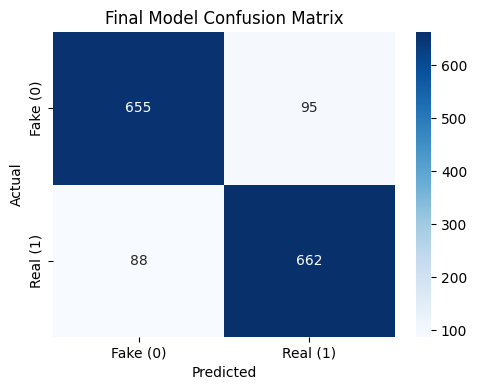

In [9]:
# CELL 9: Simplified Final Test Evaluation
import os
import torch
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("=== 1. Loading Best Fine-Tuned Model ===")
# Load the weights from the Stage 2 fine-tuning
ft_model.load_state_dict(torch.load(os.path.join(MODELS_DIR, "veritasnet_finetuned_best.pt")))
ft_model.eval()

print("=== 2. Preparing Test Data ===")
# Create the test loader for the raw images + text
ft_test_loader = DataLoader(
    EndToEndDataset(os.path.join(PROCESSED_DIR, "test_full.parquet"), X_test_sparse, y_test, preprocess),
    batch_size=16, shuffle=False
)

print("=== 3. Running Inference on Test Set ===")
all_preds, all_labels = [], []

with torch.no_grad():
    for batch in ft_test_loader:
        text = batch['text'].to(device)
        imgs = batch['img'].to(device)
        lbls = batch['label']

        # Predict: >= 0.0 logit means Class 1 (Real)
        preds = (ft_model(text, imgs) >= 0.0).float().cpu()
        all_preds.extend(preds.numpy())
        all_labels.extend(lbls.numpy())

print("\n=== 4. Final Results & Comparison ===")
final_acc = accuracy_score(all_labels, all_preds)
print(f"🎯 Final Fine-Tuned Test Accuracy : {final_acc:.4f}")
print(f"📌 Original Text-Only Baseline    : 0.7553")
print(f"🚀 Total Project Improvement      : +{(final_acc - 0.7553)*100:.2f}%\n")

print("📝 Classification Report:")
print(classification_report(all_labels, all_preds, digits=4))

# 5. Simple Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fake (0)', 'Real (1)'],
            yticklabels=['Fake (0)', 'Real (1)'])
plt.title('Final Model Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()

# Save plot
save_path = os.path.join(RESULTS_DIR, "final_confusion_matrix.png")
plt.savefig(save_path)
print(f"📊 Saved confusion matrix to: {save_path}")
plt.show()
